# Get ROMY Data

## Notebook Overview
This notebook downloads and prepares ROMY waveform data for selected events.

**Main workflow**
- Load event list and acquisition parameters.
- Fetch waveform data from configured sources.
- Apply initial preprocessing (timing, trimming, metadata context).
- Save event data files used by later analysis notebooks/scripts.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

## Configurations

Prepare the configurations to load the data

In [2]:
config = {
    # Required time window parameters
    'tbeg': "2026-04-20 07:50:00",  # Start time
    'tend': "2026-04-20 09:00:00",  # End time

    # Event information
    'origin_time': "2026-04-20 07:52:55",
    'magnitude': 7.5,

    # Station coordinates (required)
    'station_lon': 11.275476,  # BSPF longitude
    'station_lat': 48.162941,    # BSPF latitude
    
    # SEED identifiers
    'seed': "XX.ROMY..",     # Default seed ID
    'rot_seed': ["BW.ROMY.10.BJZ", "BW.ROMY..BJU", "BW.ROMY..BJV"], # "BW.ROMY.30.BJ*",  # Rotation sensor seed ID
    'tra_seed': ["GR.FUR..BHZ", "GR.FUR..BHN", "GR.FUR..BHE"],  # Translation sensor seed ID
    
    # Data source
    'data_source': "sds",  # "fdsn" | "sds" | "mseed_file"

    # Path to SDS for rotation and translation data
    'path_to_sds_rot': "/home/andbro/freenas/romy_archive/",    # SDS path for rotation data
    'path_to_sds_tra': "/home/andbro/bay200/mseed_online/archive/",  # SDS path for translation data

    # Path to inventory of rotation and translation sensor
    'path_to_inv_rot': "./metadata/station_BW_ROMY.xml",  # Rotation station inventory
    'path_to_inv_tra': "./metadata/station_GR_FUR.xml",  # Translation station inventory
    
    # Path configurations
    'workdir': "./",            # Working directory
    'path_to_data_out': "",  # Output directory

    # Set rotation of components
    'rotate_zne': True,

    # Rotate ROMY components
    'use_romy_zne': True,

    # Remove responses
    'tra_remove_response': True,
    'rot_remove_response': True,

    # Optional parameters
    'verbose': True,            # Print detailed information
}

Update config with the ouput paths for the data and the configuration

In [3]:
# get the event date
event_data = config['origin_time'][:10].replace('-', '')

# test if the event directory exists
if not os.path.exists(f"./events/event_{event_data}"):
    os.makedirs(f"./events/event_{event_data}")

config['path_to_data_out'] = f"./events/event_{event_data}/romy_{event_data}.mseed"
config['path_to_conf_out'] = f"./events/event_{event_data}/romy_data_{event_data}.yml"
config['path_to_figures'] = f"./events/event_{event_data}/figures/"

Write configurations to yaml file

In [4]:
sixdegrees.store_as_yaml(config, config['path_to_conf_out'])

 -> file ./events/event_20260420/romy_data_20260420.yml already exists. Aborting...


Setup a sixdegrees object

In [5]:
sd = sixdegrees(conf=config)

Let's load the data based on the configuration file. We also apply a resampling.

In [6]:
sd.load_data(config['tbeg'], config['tend'])

-> fetching GR.FUR..BHZ data from SDS
-> fetching GR.FUR..BHN data from SDS
-> fetching GR.FUR..BHE data from SDS
-> translation inventory provided: ./metadata/station_GR_FUR.xml
-> removing response: ACC
-> rotating translational data ZNE to ZNE
3 Trace(s) in Stream:
GR.FUR..BHZ | 2026-04-20T07:49:58.990000Z - 2026-04-20T09:00:00.990000Z | 20.0 Hz, 84041 samples
GR.FUR..BHN | 2026-04-20T07:49:58.990000Z - 2026-04-20T09:00:00.990000Z | 20.0 Hz, 84041 samples
GR.FUR..BHE | 2026-04-20T07:49:58.989999Z - 2026-04-20T09:00:00.989999Z | 20.0 Hz, 84041 samples
-> fetching BW.ROMY.10.BJZ data from SDS
-> fetching BW.ROMY..BJU data from SDS
-> fetching BW.ROMY..BJV data from SDS
-> rotation inventory provided: ./metadata/station_BW_ROMY.xml
-> removing sensitivity
-> rotated ROMY data using rotate_romy_zne (keep_z=True)
3 Trace(s) in Stream:
BW.ROMY..BJZ | 2026-04-20T07:49:58.991800Z - 2026-04-20T09:00:00.991800Z | 20.0 Hz, 84041 samples
BW.ROMY..BJN | 2026-04-20T07:49:59.003401Z - 2026-04-20T0

Ensure that all traces of stream have the same sample size

In [9]:
print(sd.st)
sd.trim_stream(set_common=True, set_interpolate=True)
print(sd.st)

6 Trace(s) in Stream:
XX.ROMY..BHZ | 2026-04-20T07:49:58.990000Z - 2026-04-20T09:00:00.990000Z | 20.0 Hz, 84041 samples
XX.ROMY..BHN | 2026-04-20T07:49:58.990000Z - 2026-04-20T09:00:00.990000Z | 20.0 Hz, 84041 samples
XX.ROMY..BHE | 2026-04-20T07:49:58.989999Z - 2026-04-20T09:00:00.989999Z | 20.0 Hz, 84041 samples
XX.ROMY..BJZ | 2026-04-20T07:49:58.991800Z - 2026-04-20T09:00:00.991800Z | 20.0 Hz, 84041 samples
XX.ROMY..BJN | 2026-04-20T07:49:59.003401Z - 2026-04-20T09:00:01.003401Z | 20.0 Hz, 84041 samples
XX.ROMY..BJE | 2026-04-20T07:49:58.993199Z - 2026-04-20T09:00:00.993199Z | 20.0 Hz, 84041 samples
 -> trim_stream: window 2026-04-20T07:49:59.003401Z -> 2026-04-20T09:00:00.989999Z
    initial npts=[84041, 84041, 84041, 84041, 84041, 84041], rates=[20.0]
    linear interpolation -> 20.0 Hz, anchored at 2026-04-20T07:49:59.003401Z
    final: starttimes={'2026-04-20T07:49:59.003401Z'}, npts={84040}, rates={20.0}
6 Trace(s) in Stream:
XX.ROMY..BHZ | 2026-04-20T07:49:59.003401Z - 2026-04

Show data for visual quality check

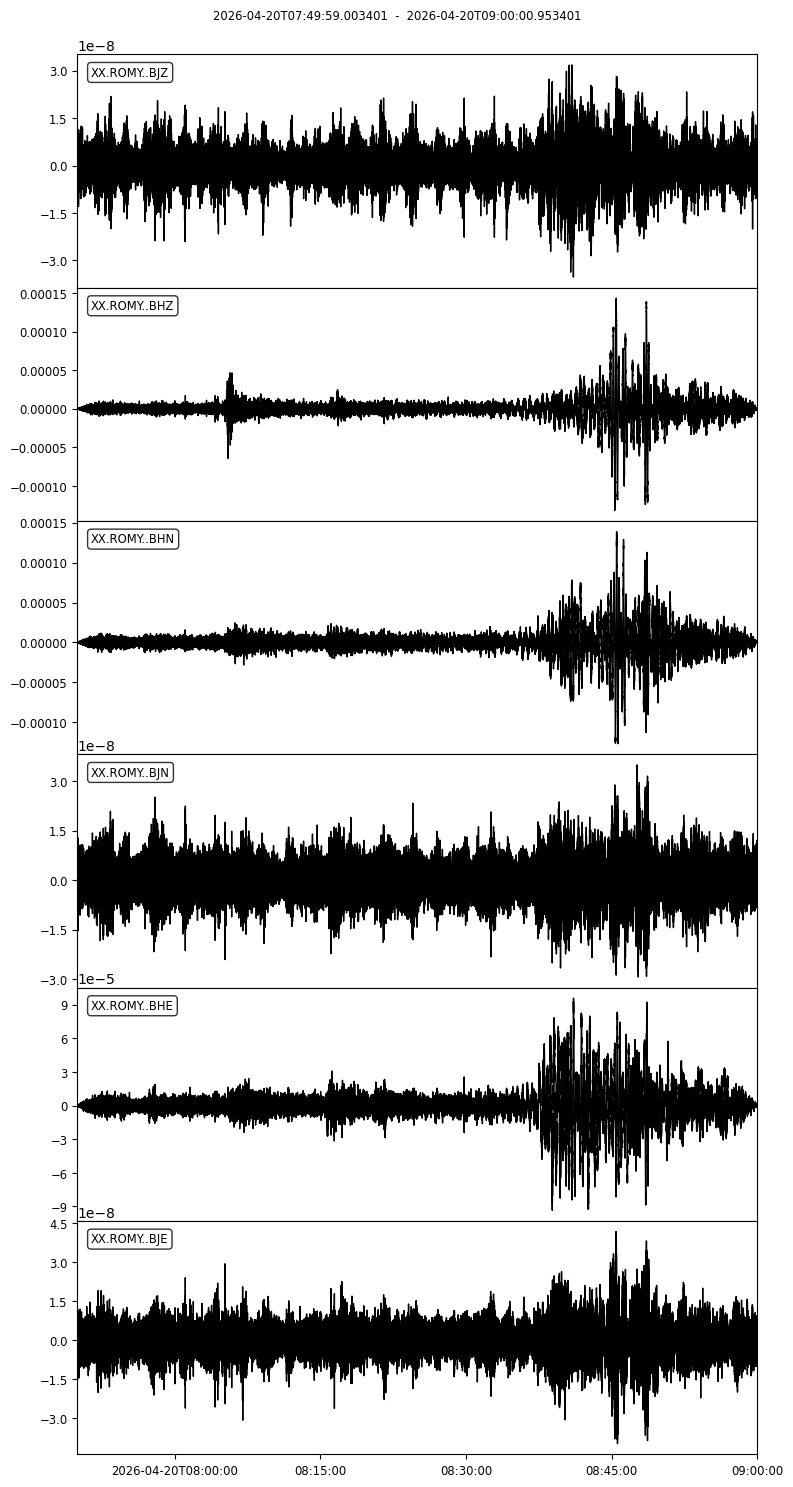

In [10]:
sd.st.plot(equal_scale=False);

Write to mseed file

In [11]:
sd.st.write(config['path_to_data_out'], format="MSEED")

/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/io/mseed/core.py:773: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)
